In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
results = pd.read_csv('../summary.csv')

In [35]:
results = results.drop(['attack_subset', 'samples_total', 'samples_bonafide', 'samples_spoof', 'checkpoint_sha256', 'metrics_path'], axis = 1)

In [36]:
results_eval = results[results['split'] == 'eval']
results_dev = results[results['split'] == 'dev']

In [37]:
results_eval = results_eval.drop('split', axis = 1)
results_dev = results_dev.drop('split', axis = 1)

In [38]:
results_eval

,frontend,threshold_free_eer,threshold_free_auc,dev_eer_threshold,fpr_at_0.5,spoof_recall_at_0.5
1,mel64,0.130115,0.943375,0.836578,0.246635,0.924361
3,mel128,0.114087,0.953627,0.916409,0.196057,0.923155
5,mel256,0.113118,0.952456,0.831765,0.115296,0.887997
7,linear_stft,0.139802,0.937073,0.894476,0.169409,0.879606
9,mfcc40,0.185621,0.896336,0.844174,0.393066,0.902727
11,randproj128,0.170368,0.906382,0.802520,0.554589,0.936837


In [63]:
results_eval = results_eval.sort_values(by='threshold_free_auc', ascending=False)

In [64]:
results_eval = results_eval.reset_index()

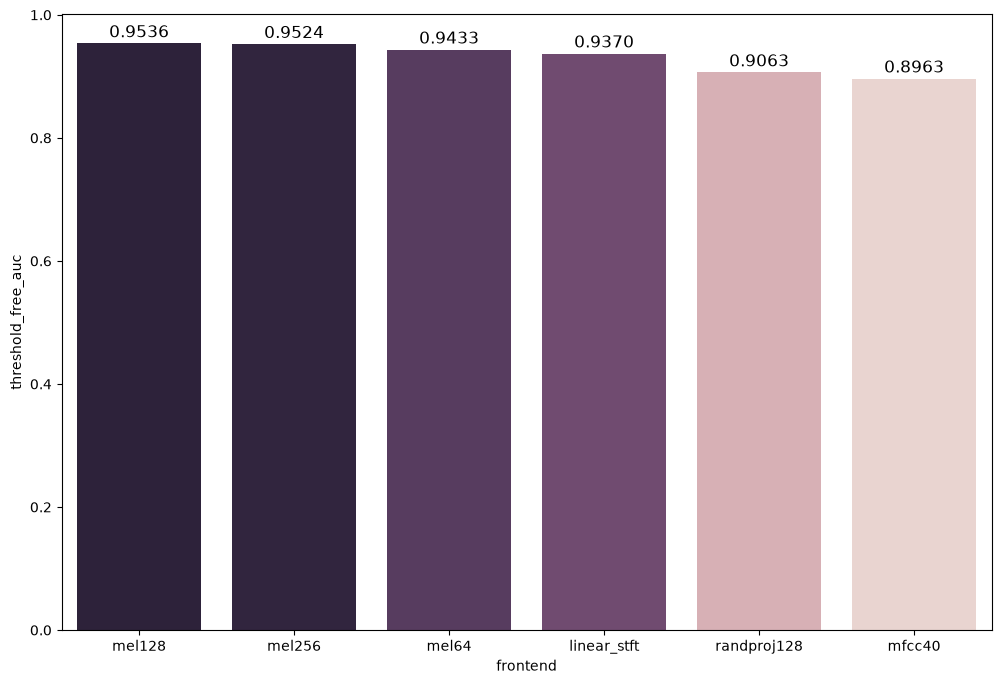

In [65]:
plt.subplots(figsize=(12,8))
ax=sns.barplot(x='frontend', y="threshold_free_auc", data=results_eval, hue = "threshold_free_auc", legend = False)
labels = (results_eval["threshold_free_auc"])
# add result numbers on barchart
for i, v in enumerate(labels):
    ax.text(i, v + 0.01, str(v)[0:6], horizontalalignment = 'center', size = 12, color = 'black')

In [68]:
results_eval = results_eval.sort_values(by='threshold_free_eer', ascending=True)

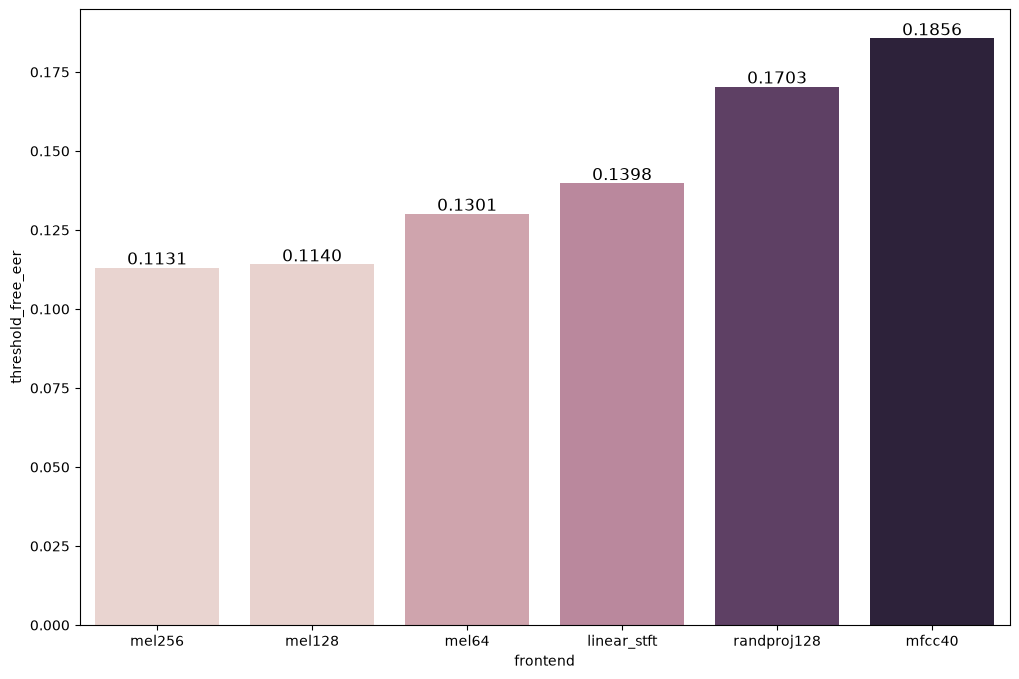

In [71]:
plt.subplots(figsize=(12,8))
ax=sns.barplot(x='frontend', y="threshold_free_eer", data=results_eval, hue = "threshold_free_eer", legend = False)
labels = (results_eval["threshold_free_eer"])
# add result numbers on barchart
for i, v in enumerate(labels):
    ax.text(i, v + 0.001, str(v)[0:6], horizontalalignment = 'center', size = 12, color = 'black')